# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

# 0. Document Instructions

## 0.1. Git Version Control

After making modifications, please use Colab's function of "Save in Github to keep changes" (Github authorization required) to commit the changes to the repository (Your own branch if needed).

**NOTE**: When A modifies this notebook, but have not commited to Github, if B opens this notebook, they will see the Github old version.

## 0.2. Handle persistent data storage

Mount Google Drive instead of relying on Colab's temporary run-time storage.

**IMPORTANT:** Although Google Colab allows collaboration of the notebook, data and folders are originally in Junxuan's drive, this could cause issues when refering to the mounted directory path. To allow the code to work for all of us, (who's not junxuan) please create a **short-cut** of Junxuan's shared folder in our own Google Drive, path `MyDrive/`.

In [1]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 0.3 Setup and data loading

Run the notebook from top to bottom after Step 1, Step 2, Task 3 and Task 4 have been run once per model, with `MODEL` at their top set to that model. It parses and verifies nothing again; for every model it reads what Steps 1 to 3 saved in `evaluation_runs/<model>/processed/`:

| File | Saved by | Used for |
|---|---|---|
| `explanation_lemmas.parquet` | Step 1 (preprocessing) | Explanation ids with their persona, recipe and rank |
| `explanation_docs.spacy` | Step 2 (2.1.5) | Explanation texts, for the length |
| `verified_claims.parquet` | Step 2 (2.2.5) | Every claim with its verdict |
| `transparency_levels.parquet` | Task 3 (3.5) | Transparency level and score of every explanation |

A model whose files are missing is skipped, so the notebook also runs before every model has been processed. The last cell saves the comparison tables in `evaluation_runs/comparison/`; nothing else is written.

In [2]:
%pip install -q spacy pyarrow statsmodels

In [3]:
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from scipy import stats
from spacy.tokens import DocBin
from statsmodels.stats.multitest import multipletests

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
runs_dir = project_dir / "evaluation_runs"

# folder name -> name in tables and plots, in a fixed order (the original model first)
MODELS = {
    "gpt-4o-mini": "GPT-4o-mini",
    "gpt-oss-120b": "GPT-OSS-120B",
    "qwen3.8-27b": "Qwen3.8-27B",
}

# one colour per model, always the same (validated categorical palette)
MODEL_COLORS = {
    "GPT-4o-mini": "#2a78d6",
    "GPT-OSS-120B": "#eb6834",
    "Qwen3.8-27B": "#1baf7a",
}

# files that Steps 1 to 3 save for every model
NEEDED_FILES = [
    "explanation_lemmas.parquet",
    "explanation_docs.spacy",
    "verified_claims.parquet",
    "transparency_levels.parquet",
]

In [4]:
# a blank pipeline only reads the saved parses, nothing is parsed here
blank_nlp = spacy.blank("en")


def load_model(folder):
    """Read one model's saved outputs; None and the missing files when it has not been processed yet."""
    processed = runs_dir / folder / "processed"
    missing = [name for name in NEEDED_FILES if not (processed / name).exists()]
    if missing:
        return None, missing

    # explanation ids: "<persona id>_rank_<rank>", with persona, recipe and rank
    index = pd.read_parquet(processed / "explanation_lemmas.parquet")[
        ["recommendation_id", "persona_id", "recipe_id", "rank"]
    ]
    # explanation texts as parsed in Step 2
    texts = {
        doc.user_data["recommendation_id"]: doc.text
        for doc in DocBin().from_disk(processed / "explanation_docs.spacy").get_docs(blank_nlp.vocab)
    }
    claims = pd.read_parquet(processed / "verified_claims.parquet")
    levels = pd.read_parquet(processed / "transparency_levels.parquet")
    return {"index": index, "texts": texts, "claims": claims, "levels": levels}, []

In [5]:
# load every model that has been processed
model_data = {}
for folder, name in MODELS.items():
    data, missing = load_model(folder)
    if data is None:
        print(f"{name}: skipped, not found in {runs_dir / folder / 'processed'}: {', '.join(missing)}")
        continue
    model_data[name] = data
    print(f"{name}: {len(data['index'])} explanations, {len(data['claims'])} claims")

model_names = list(model_data)
assert model_names, "no model has been processed yet"

GPT-4o-mini: 536 explanations, 1551 claims
GPT-OSS-120B: 536 explanations, 3609 claims
Qwen3.8-27B: 536 explanations, 2825 claims


# 6. Evaluation & Comparison

The original GPT-4o-mini explanations are compared with the explanations that the other models wrote for the same persona + recipe + rank triples.

## 6.1 Metrics per explanation

| Metric | Counted per | Definition |
|---|---|---|
| Factual accuracy | claim | supported claims / (supported + contradicted claims); unverified claims are left out and their share is reported separately |
| Hallucination rate | explanation | share of explanations with at least one contradicted claim (Task 2) |
| Transparency score | explanation | mean score, High = 2, Medium = 1, Low = 0 (Task 3) |
| Average length | explanation | words per explanation, same rule as 1.2b and 4.2a |

In [6]:
# the same word rule as 1.2b (Step 1) and 4.2a (Task 4)
WORD_PATTERN = r"\b\w+(?:[-'’]\w+)*\b"
VERDICTS = ["supported", "contradicted", "unverified"]


def explanation_table(data):
    """One row per explanation: length, claims by verdict, hallucination flag, transparency."""
    table = data["index"].copy()

    # words per explanation
    table["word_count"] = (
        table["recommendation_id"].map(data["texts"]).str.findall(WORD_PATTERN).str.len()
    )

    # claims of each verdict; an explanation without claims gets zeros
    verdicts = pd.crosstab(
        data["claims"]["recommendation_id"], data["claims"]["verification_status"]
    ).reindex(columns=VERDICTS, fill_value=0)
    table = table.merge(verdicts, left_on="recommendation_id", right_index=True, how="left")
    table[VERDICTS] = table[VERDICTS].fillna(0).astype(int)
    table["claims"] = table[VERDICTS].sum(axis=1)

    # hallucinated: at least one contradicted claim (Task 2)
    table["hallucinated"] = table["contradicted"].gt(0).astype(int)

    # transparency level and score (Task 3)
    table = table.merge(
        data["levels"][["recommendation_id", "level", "score"]],
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
    assert table["word_count"].notna().all(), "explanations without a text"
    assert table["score"].notna().all(), "explanations without a transparency level"
    return table

In [7]:
explanations = pd.concat(
    [explanation_table(data).assign(model=name) for name, data in model_data.items()],
    ignore_index=True,
)

# every model explained the same recommendations, so the rows pair up
id_sets = explanations.groupby("model")["recommendation_id"].apply(frozenset)
assert id_sets.nunique() == 1, "models explain different recommendations"

display(explanations.head())

,recommendation_id,persona_id,recipe_id,rank,word_count,supported,contradicted,unverified,claims,hallucinated,level,score,model
0,user_01_rank_01,user_01,81968,1,40,2,1,1,4,1,High,2,GPT-4o-mini
1,user_01_rank_02,user_01,10614,2,34,2,0,2,4,0,Medium,1,GPT-4o-mini
2,user_01_rank_03,user_01,94673,3,34,3,0,1,4,0,High,2,GPT-4o-mini
3,user_01_rank_04,user_01,364252,4,36,1,1,2,4,1,Medium,1,GPT-4o-mini
4,user_01_rank_05,user_01,12569,5,29,1,1,1,3,1,Medium,1,GPT-4o-mini


## 6.2 Model comparison table

All explanations of a model pooled; the persona-level version is in 6.4.

In [8]:
def summarize(group):
    """The four metrics for one model, plus the counts behind them."""
    verifiable = group["supported"].sum() + group["contradicted"].sum()
    return pd.Series({
        "explanations": len(group),
        "factual accuracy (%)": 100 * group["supported"].sum() / verifiable,
        "hallucination rate (%)": 100 * group["hallucinated"].mean(),
        "transparency score": group["score"].mean(),
        "average length (words)": group["word_count"].mean(),
        "claims per explanation": group["claims"].mean(),
        "unverified claims (%)": 100 * group["unverified"].sum() / group["claims"].sum(),
    })

In [9]:
comparison = pd.DataFrame({
    name: summarize(explanations[explanations["model"] == name]) for name in model_names
}).T
display(comparison.round(2))

# share of each transparency level per model (%)
level_share = (
    pd.crosstab(explanations["model"], explanations["level"], normalize="index")
    .reindex(index=model_names, columns=["High", "Medium", "Low"], fill_value=0)
    * 100
)
display(level_share.round(1))

,explanations,factual accuracy (%),hallucination rate (%),transparency score,average length (words),claims per explanation,unverified claims (%)
GPT-4o-mini,536.0,79.05,27.05,1.57,35.24,2.89,47.07
GPT-OSS-120B,536.0,78.77,45.71,1.98,61.45,6.73,51.98
Qwen3.8-27B,536.0,82.36,33.40,1.98,58.14,5.27,50.44


level,High,Medium,Low
model,,,
GPT-4o-mini,59.7,37.7,2.6
GPT-OSS-120B,97.8,2.2,0.0
Qwen3.8-27B,97.8,2.2,0.0


## 6.3 Contradicted claims by claim type

In [10]:
# claims of every model, with their verdicts
claims_all = pd.concat(
    [data["claims"].assign(model=name) for name, data in model_data.items()],
    ignore_index=True,
)

type_rows = []
for (name, claim_type), group in claims_all.groupby(["model", "claim_type"]):
    supported = group["verification_status"].eq("supported").sum()
    contradicted = group["verification_status"].eq("contradicted").sum()
    # explanations with at least one contradicted claim of this type
    flagged = group.loc[group["verification_status"].eq("contradicted"), "recommendation_id"].nunique()
    type_rows.append({
        "model": name,
        "claim type": claim_type,
        "claims": len(group),
        "factual accuracy (%)": 100 * supported / (supported + contradicted) if supported + contradicted else np.nan,
        "explanations with a contradicted claim (%)": 100 * flagged / len(model_data[name]["index"]),
    })

by_type = pd.DataFrame(type_rows)
by_type["model"] = pd.Categorical(by_type["model"], categories=model_names, ordered=True)
by_type = by_type.sort_values(["claim type", "model"]).reset_index(drop=True)
display(by_type.round(1))

,model,claim type,claims,factual accuracy (%),explanations with a contradicted claim (%)
0,GPT-4o-mini,ingredient,504,86.2,8.8
1,GPT-OSS-120B,ingredient,1464,78.5,35.3
2,Qwen3.8-27B,ingredient,1182,81.0,25.0
3,GPT-4o-mini,label,252,60.0,0.7
4,GPT-OSS-120B,label,948,54.7,4.5
5,Qwen3.8-27B,label,737,53.8,4.3
6,GPT-4o-mini,nutrient,795,73.0,19.4
7,GPT-OSS-120B,nutrient,1197,82.9,11.8
8,Qwen3.8-27B,nutrient,906,89.7,7.3


## 6.4 Compare per persona

The explanations are nested in 40 personas, so each metric is first computed per persona (factual accuracy over the persona's claims). The persona values are paired across models, because every model explained the same recommendations.

In [11]:
METRICS = [
    "factual accuracy (%)",
    "hallucination rate (%)",
    "transparency score",
    "average length (words)",
]


def persona_metrics(table):
    """The four metrics per persona for one model."""
    by_persona = table.groupby("persona_id")
    supported = by_persona["supported"].sum()
    verifiable = supported + by_persona["contradicted"].sum()
    return pd.DataFrame({
        "factual accuracy (%)": 100 * supported / verifiable.replace(0, np.nan),
        "hallucination rate (%)": 100 * by_persona["hallucinated"].mean(),
        "transparency score": by_persona["score"].mean(),
        "average length (words)": by_persona["word_count"].mean(),
    })

In [12]:
persona_df = pd.concat(
    {name: persona_metrics(explanations[explanations["model"] == name]) for name in model_names},
    names=["model", "persona_id"],
).reset_index()
print("Personas per model:", persona_df.groupby("model").size().to_dict())

# mean and standard deviation over the personas
persona_summary = persona_df.groupby("model")[METRICS].agg(["mean", "std"]).reindex(model_names)
display(persona_summary.round(2))

Personas per model: {'GPT-4o-mini': 40, 'GPT-OSS-120B': 40, 'Qwen3.8-27B': 40}


factual accuracy (%)        hallucination rate (%)         \
                             mean    std                   mean    std   
model                                                                    
GPT-4o-mini                 77.86  16.86                  27.57  18.00   
GPT-OSS-120B                79.73  11.80                  45.82  22.16   
Qwen3.8-27B                 83.52  10.39                  34.13  20.59   

             transparency score       average length (words)        
                           mean   std                   mean   std  
model                                                               
GPT-4o-mini                1.57  0.20                  35.29  3.87  
GPT-OSS-120B               1.98  0.05                  61.43  3.54  
Qwen3.8-27B                1.98  0.04                  58.17  2.90

### Paired tests

Friedman test over all models and Wilcoxon signed-rank test for every pair of models, on the persona values; one Benjamini-Hochberg correction over all tests, as in Task 4. The results are exploratory.

In [13]:
def paired_values(metric, models):
    """Persona x model values of one metric, keeping personas with a value for every model."""
    wide = persona_df.pivot(index="persona_id", columns="model", values=metric)
    return wide[list(models)].dropna()


test_rows = []
if len(model_names) < 2:
    print("Paired tests need at least two processed models; skipped.")

for metric in METRICS if len(model_names) >= 2 else []:
    # all models together (Friedman needs three or more)
    if len(model_names) >= 3:
        wide = paired_values(metric, model_names)
        statistic, p = stats.friedmanchisquare(*[wide[name] for name in model_names])
        test_rows.append({
            "metric": metric, "comparison": " / ".join(model_names), "test": "Friedman",
            "personas": len(wide), "statistic": statistic, "p": p,
        })

    # every pair of models; the difference is the second model minus the first
    for first, second in combinations(model_names, 2):
        wide = paired_values(metric, [first, second])
        difference = wide[second] - wide[first]
        if difference.eq(0).all():
            statistic, p = np.nan, np.nan
        else:
            statistic, p = stats.wilcoxon(wide[first], wide[second])
        test_rows.append({
            "metric": metric, "comparison": f"{second} vs {first}", "test": "Wilcoxon signed-rank",
            "personas": len(wide), "statistic": statistic, "p": p,
            "median difference": difference.median(),
            "personas higher in second": int(difference.gt(0).sum()),
            "personas higher in first": int(difference.lt(0).sum()),
        })

tests = pd.DataFrame(test_rows)
if not tests.empty:
    # one Benjamini-Hochberg correction over all tests
    valid = tests["p"].notna()
    tests.loc[valid, "p_fdr"] = multipletests(tests.loc[valid, "p"], method="fdr_bh")[1]
    tests["significant after FDR"] = tests["p_fdr"].lt(0.05)
    display(tests.round(4))

,metric,comparison,test,personas,statistic,p,median difference,personas higher in second,personas higher in first,p_fdr,significant after FDR
0,factual accuracy (%),GPT-4o-mini / GPT-OSS-120B / Qwen3.8-27B,Friedman,40,4.3145,0.1156,NaN,NaN,NaN,0.1322,False
1,factual accuracy (%),GPT-OSS-120B vs GPT-4o-mini,Wilcoxon signed-rank,40,387.0000,0.7648,-0.4669,20.0,20.0,0.7648,False
2,factual accuracy (%),Qwen3.8-27B vs GPT-4o-mini,Wilcoxon signed-rank,40,269.0000,0.0913,4.2595,23.0,16.0,0.1124,False
3,factual accuracy (%),Qwen3.8-27B vs GPT-OSS-120B,Wilcoxon signed-rank,40,225.0000,0.0120,2.9919,27.0,13.0,0.0175,True
4,hallucination rate (%),GPT-4o-mini / GPT-OSS-120B / Qwen3.8-27B,Friedman,40,18.9272,0.0001,NaN,NaN,NaN,0.0002,True
5,hallucination rate (%),GPT-OSS-120B vs GPT-4o-mini,Wilcoxon signed-rank,40,110.0000,0.0002,14.8352,29.0,9.0,0.0003,True
6,hallucination rate (%),Qwen3.8-27B vs GPT-4o-mini,Wilcoxon signed-rank,40,213.5000,0.0604,7.4176,22.0,14.0,0.0806,False
7,hallucination rate (%),Qwen3.8-27B vs GPT-OSS-120B,Wilcoxon signed-rank,40,117.5000,0.0004,-13.3333,7.0,30.0,0.0007,True
8,transparency score,GPT-4o-mini / GPT-OSS-120B / Qwen3.8-27B,Friedman,40,68.9767,0.0000,NaN,NaN,NaN,0.0000,True
9,transparency score,GPT-OSS-120B vs GPT-4o-mini,Wilcoxon signed-rank,40,0.0000,0.0000,0.4143,39.0,0.0,0.0000,True


## 6.5 Plot the persona-level metrics

Each dot is one persona; the line marks the mean over the personas.

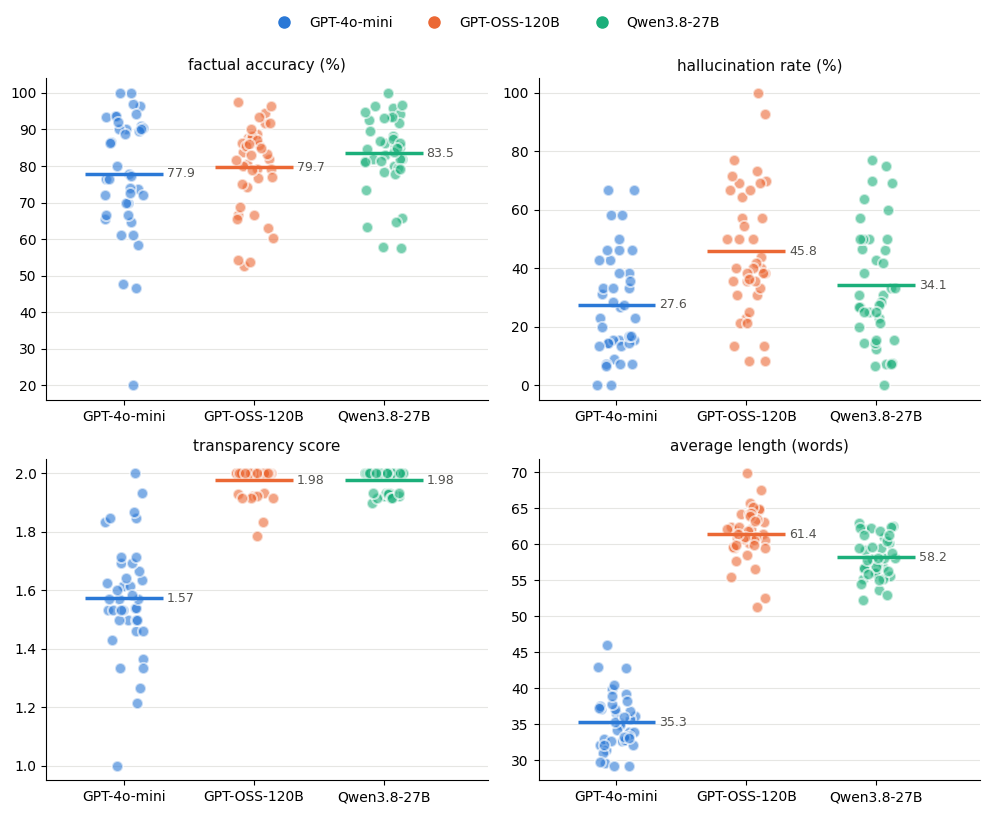

In [14]:
# one panel per metric, the models side by side
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
rng = np.random.default_rng(0)

for ax, metric in zip(axes.flat, METRICS):
    for position, name in enumerate(model_names):
        values = persona_df.loc[persona_df["model"] == name, metric].dropna()
        # persona dots, spread sideways so they do not overlap
        jitter = rng.uniform(-0.15, 0.15, len(values))
        ax.scatter(
            position + jitter, values, s=64, color=MODEL_COLORS[name], alpha=0.6,
            edgecolors="white", linewidths=1.5, zorder=2,
        )
        # mean over the personas, labelled in text colour
        mean = values.mean()
        ax.hlines(mean, position - 0.3, position + 0.3, color=MODEL_COLORS[name], linewidth=2.5, zorder=3)
        label = f"{mean:.2f}" if metric == "transparency score" else f"{mean:.1f}"
        ax.annotate(label, (position + 0.33, mean), va="center", fontsize=9, color="#52514e")

    ax.set_xticks(range(len(model_names)), model_names)
    ax.set_xlim(-0.6, len(model_names) - 0.2)
    ax.set_title(metric, fontsize=11, color="#0b0b0b")
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

handles = [
    plt.Line2D([], [], marker="o", linestyle="", markersize=8, color=MODEL_COLORS[name], label=name)
    for name in model_names
]
fig.legend(handles=handles, loc="upper center", ncol=len(model_names), frameon=False, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

## 6.6 Save the comparison tables

In [15]:
# comparison tables in their own folder; nothing else is written
comparison_dir = runs_dir / "comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(comparison_dir / "model_comparison.csv")
persona_df.to_csv(comparison_dir / "persona_metrics_by_model.csv", index=False)
by_type.to_csv(comparison_dir / "claim_types_by_model.csv", index=False)
if not tests.empty:
    tests.to_csv(comparison_dir / "paired_tests.csv", index=False)
print("Saved to", comparison_dir)

Saved to /content/drive/MyDrive/XFoodRec_Project_Data/evaluation_runs/comparison
